# Alignment quality of the unmasked chr22 alignments

Run this notebook using cog2026.10.22_En0.7.9 conda environment

Sum-of-pairs score (cogent3 `sp_score`) in non-overlapping windows of the
per-fragment unmasked alignments in `<region>/nonmasked_alldata_chrm22/`, written by
`filtering_databank_masked_nointrons.py` (`omit_degenerates` + `omit_gap_pos`), for
the regions in `DATA_DIRS`. The per-window distributions are overlaid in one
histogram.

`sp_score` turns each pairwise genetic distance into an estimated number of
unchanged positions, subtracts an affine gap penalty (`gap_insert=12`, `gap_extend=1`
by default), and sums over the three species pairs. With 3 sequences and a window of
`WINDOW` columns the maximum is `3 * WINDOW` (three identical, gap-free sequences);
gap-dominated windows go strongly negative.

Each region gets its own data frame in `windows_by_region`, one row per window:
`file` (fragment file name), `window` (0-based index within the file), `col_start` /
`col_end` (half-open alignment-column interval within the filtered file, not genomic
positions), `sp_score` (`NaN` if the app returned NotCompleted) and `failed`. The
trailing partial window of each file is dropped so every score is on the same number
of columns.


In [102]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cogent3 import load_aligned_seqs, make_aligned_seqs, get_app

import paths

In [ ]:
# region label -> directory of per-fragment .fa alignments (top level only; subfolders ignored)
DATA_DIRS = {
    "intergenicAR": paths.DATA_HUMCHIMPORANGOR114 + "intergenicAR/nonmasked_alldata_chrm22",
    "distalIG": paths.DATA_HUMCHIMPORANGOR114 + "distalIG/nonmasked_alldata_chrm22",
}

REGIONS = list(DATA_DIRS)

WINDOW = 60  # bp
if WINDOW % 3 != 0:
    raise ValueError(f"To keep compatibility with trinucleotide substitution modelsWINDOW must be a multiple of 3; got {WINDOW}")

# window size for labels and file names: "1kb", "2kb", ... for multiples of 1000, otherwise e.g. "500bp"
WINDOW_TAG = f"{WINDOW // 1000}kb" if WINDOW % 1000 == 0 else f"{WINDOW}bp"
folder_out_plots = "output_data/alignment_quality"
FIG_DIR = Path(folder_out_plots)  # created if missing

THRESHOLD_FILTER = 0.5  # fraction of contigous sites in a window that must be non-gap for the window to be considered "good"

# default sp_score settings; calc="pdist" avoids NaN distances on very divergent windows
sp_score = get_app("sp_score", calc="JC69", gap_insert=12.0, gap_extend=1.0)

In [104]:
def window_sp_scores(aln, window, app):
    """One record per non-overlapping window of `window` columns.

    The trailing partial window is dropped so every score is on the same
    number of columns. Windows the app cannot score (NotCompleted) are kept
    with sp_score = NaN and failed = True.
    """
    records = []
    for i, start in enumerate(range(0, len(aln) - window + 1, window)):
        result = app(aln[start : start + window])
        failed = not isinstance(result, float)
        records.append(
            {
                "window": i,
                "col_start": start,
                "col_end": start + window,
                "sp_score": np.nan if failed else result,
                "failed": failed,
            }
        )
    return records


In [105]:
WINDOW_COLUMNS = ["file", "window", "col_start", "col_end", "sp_score", "failed"]

windows_by_region = {}  # region -> DataFrame, one row per window
scores = {}  # region -> array of successful sp_scores (used by the histogram)
summary = []
for region in REGIONS:
    fnames = sorted(p for p in Path(DATA_DIRS[region]).glob("*.fa") if p.is_file())
    records, file_length = [], 0
    for fname in fnames:
        aln = load_aligned_seqs(fname, moltype="dna")  # default allowed_gap_frac drops only columns that are gaps in every sequence
        for rec in window_sp_scores(aln, WINDOW, sp_score):
            rec["file"] = fname.name
            records.append(rec)
        file_length += len(aln)
    windows_by_region[region] = df = pd.DataFrame(records, columns=WINDOW_COLUMNS)
    scores[region] = s = df["sp_score"].dropna().to_numpy()
    summary.append(
        {
            "region": region,
            "n_files": len(fnames),
            "file_length": file_length,
            "n_windows": len(s),
            "failed_windows": int(df["failed"].sum()),
            "mean": s.mean(),
            "median": np.median(s),
            "q05": np.quantile(s, 0.05),
            "q95": np.quantile(s, 0.95),
            "frac_negative": (s < 0).mean(),
        }
    )

summary = pd.DataFrame(summary).set_index("region")
summary


,n_files,file_length,n_windows,failed_windows,mean,median,q05,q95,frac_negative
region,,,,,,,,,
intergenicAR,551,3495406,57973,21,68.422727,166.294847,-144.0,177.977443,0.310765
distalIG,185,1155301,19166,1,122.405694,171.719317,-144.0,180.000000,0.142753


The regions differ ~5x in length, so the histograms are drawn as densities on a
shared set of bins; otherwise `intronsAR` would swamp the other two.

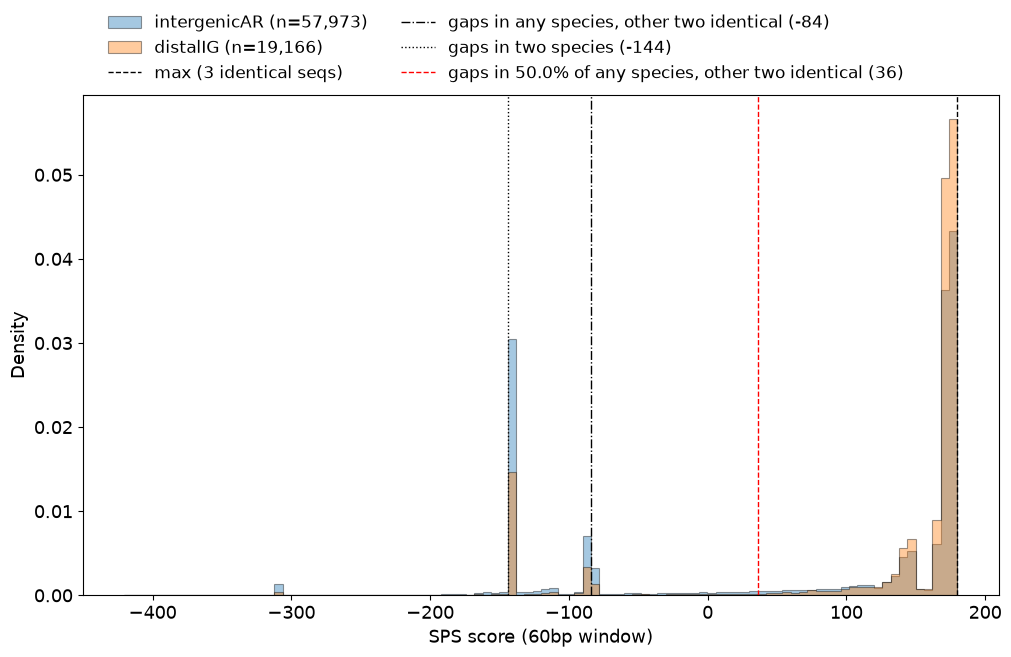

In [106]:
all_scores = np.concatenate(list(scores.values()))
bins = np.linspace(all_scores.min(), all_scores.max(), 101)

# reference scores for two extreme windows, computed with the same function:
# one species entirely gaps while the other two are identical: WINDOW - 2 (12 + WINDOW)
# two species entirely gaps (they share the same gap run): -2 (12 + WINDOW)


n_non_gap = round(WINDOW * THRESHOLD_FILTER)
full = "A" * WINDOW
threshold = "A" * n_non_gap + "-" * (WINDOW - n_non_gap)
empty = "-" * WINDOW
reference_scores = {
    "gaps in any species, other two identical": sp_score(
        make_aligned_seqs({"a": full, "b": full, "c": empty}, moltype="dna")
    ),
    "gaps in two species": sp_score(
        make_aligned_seqs({"a": full, "b": empty, "c": empty}, moltype="dna")
    ),
    f"gaps in {THRESHOLD_FILTER:.1%} of any species, other two identical": sp_score(
            make_aligned_seqs({"a": full, "b": full, "c": threshold}, moltype="dna")
        )
}

# fixed font sizes; setting them (rather than adding to the current size) keeps the
# figure identical however many times this cell is run
FONT_SIZE = 13
plt.rcParams.update(
    {key: FONT_SIZE for key in ("font.size", "axes.labelsize", "xtick.labelsize", "ytick.labelsize")}
)
plt.rcParams["legend.fontsize"] = FONT_SIZE - 1

# constrained layout gives the legend its own space above the axes, so the plot keeps its size
fig, ax = plt.subplots(figsize=(10, 6.5), layout="constrained")
for region in REGIONS:
    ax.hist(
        scores[region],
        bins=bins,
        density=True,
        histtype="stepfilled",
        alpha=0.4,
        edgecolor="black",
        linewidth=0.8,
        label=f"{region} (n={len(scores[region]):,})",
    )
ax.axvline(3 * WINDOW, color="black", linestyle="--", linewidth=1, label="max (3 identical seqs)")
for (label, value), style, colorstyle in zip(reference_scores.items(), ("-.", ":", "--"), ("black", "black", "red")):
    ax.axvline(value, color=colorstyle, linestyle=style, linewidth=1, label=f"{label} ({value:.0f})")
ax.set_xlabel(f"SPS score ({WINDOW_TAG} window)")
ax.set_ylabel("Density")
# legend above the plot, outside the axes
fig.legend(loc="outside upper center", ncol=2, frameon=False)
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(folder_out_plots + f"alignment_quality_spscore_{WINDOW_TAG}.png", dpi=150)
plt.show()